# Test 2, Part B

**Choose exactly two of the three problems. Each selected problem is worth 8 points (50% of Part B), for a total of 16 points. State your choices below; only those two problems will be graded.**

**Selected problems:** Replace this text with your two problem numbers.

This is individual, open-resource work. Submit one `.ipynb` notebook with the code, outputs, and responses for your selected problems.

For each selected problem, interpret the supplied results and state a specific claim addressing its research question. Make one additional analytical move to investigate your claim, producing a chart, table, or numerical result. Explain how that evidence supports, qualifies, or challenges your claim, and give your recommendation to Harbor Supply. One well-chosen addition per problem is sufficient.

Each selected problem is scored as follows:

| Evidence | Points |
| --- | ---: |
| Interpretation and specific claim | 2 |
| Appropriate additional analysis and resulting artifact | 3 |
| Interpretation of the added evidence and recommendation | 3 |
| **Total per problem** | **8** |

## Problem 1 — Clustering: Choosing Service Groups

### The Problem

Harbor Supply wants to organize all its accounts into service groups. Each group will share an arrangement for planning weekly delivery capacity. Accounts with similar order volumes and week-to-week variability should be easier to serve through a common arrangement. Management can administer either two or three arrangements; each additional arrangement requires more coordination.

**Research question:** Should Harbor Supply organize its accounts into two or three service groups to accommodate differences in average weekly orders and week-to-week variability?

An analyst has fitted K-means with K=2 and K=3. The data preparation and initial analysis are supplied below.

The synthetic records summarize weekly orders for 120 accounts over the same 26-week period.

| Column | Meaning |
| --- | --- |
| `orders_per_week` | Mean number of orders per week |
| `weekly_order_sd` | Standard deviation of the weekly order counts; larger values indicate more week-to-week variation |

Both columns are used for clustering and shown in the plots.

### Supplied Analysis

Run the following cells. Both fits use the same standardized measurements. Group numbers identify groups within each fit.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

data_url = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/main/"
    "tests/test2/data/service-accounts.csv"
)
paths = [Path("data/service-accounts.csv"), Path("content/tests/test2/data/service-accounts.csv")]
data_source = next((path for path in paths if path.is_file()), data_url)
accounts = pd.read_csv(data_source).set_index("account_id")
cluster_features = ["orders_per_week", "weekly_order_sd"]
cluster_X = StandardScaler().fit_transform(accounts[cluster_features])
print(f"Loaded {len(accounts)} accounts.")

In [ ]:
cluster_fits = {}
cluster_labels = pd.DataFrame(index=accounts.index)
cluster_scores = {}
for k in (2, 3):
    model = KMeans(n_clusters=k, n_init=20, random_state=7130).fit(cluster_X)
    cluster_fits[k] = model
    cluster_labels[f"K={k}"] = model.labels_ + 1
    cluster_scores[f"K={k}"] = silhouette_score(cluster_X, model.labels_)
display(pd.Series(cluster_scores, name="Silhouette").round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True, layout="constrained")
for k, ax in zip((2, 3), axes):
    for group in sorted(cluster_labels[f"K={k}"].unique()):
        cluster_rows = accounts.loc[cluster_labels[f"K={k}"].eq(group)]
        ax.scatter(cluster_rows["orders_per_week"], cluster_rows["weekly_order_sd"],
                   label=f"Group {group}", s=24, alpha=0.75)
    ax.set(title=f"K={k}", xlabel="Orders per week")
    ax.legend()
axes[0].set_ylabel("Standard deviation of weekly orders")
plt.show()

### Your Work

In [ ]:
# Problem 1: Your additional analysis.

> Replace this text with your response to Problem 1.

## Problem 2 — Anomaly Detection: Prioritizing Inspections

### The Problem

Harbor Supply operates pumps at its facilities. The maintenance team can give detailed inspections to 20 pumps from each batch of 200. Its goal is to find pumps with faults. It is considering Local Outlier Factor (LOF) and Isolation Forest to prioritize inspections using vibration and temperature readings.

**Research question:** Which detector, if either, should Harbor Supply use to prioritize 20 inspections per 200-pump batch?

An analyst has applied both detectors to a past batch and selected the 20 highest-scoring pumps under each method. All 200 pumps in this batch subsequently received the same bench inspection, performed without access to the detector scores. The measurements and complete inspection outcomes are available for assessing the proposed policy for future comparable batches.

The records are synthetic. All measurements were taken under the same nominal operating conditions.

| Column | Meaning | Use |
| --- | --- | --- |
| `vibration_mm_s` | Vibration velocity in millimetres per second | Detector input |
| `temperature_c` | Temperature in degrees Celsius | Detector input |
| `confirmed_fault` | Bench inspection outcome: 1 for a confirmed fault, 0 otherwise | Independent outcome for assessing the inspection policy |

Both detectors use the two measurements shown in the plots. Inspection outcomes are available for your investigation and are excluded from fitting.

### Supplied Analysis

Run the following cells. The measurements are standardized, both models score the same collection, and each selects exactly 20 pumps. Larger scores indicate greater unusualness under the respective method.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

data_url = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/main/"
    "tests/test2/data/pump-inspections.csv"
)
paths = [Path("data/pump-inspections.csv"), Path("content/tests/test2/data/pump-inspections.csv")]
data_source = next((path for path in paths if path.is_file()), data_url)
pumps = pd.read_csv(data_source).set_index("pump_id")
pump_features = ["vibration_mm_s", "temperature_c"]
pump_X = StandardScaler().fit_transform(pumps[pump_features])
print(f"Loaded {len(pumps)} pumps and their inspection outcomes.")

Loaded 200 pumps and their inspection outcomes.


,Pumps selected
LOF,20
Isolation Forest,20


Pumps selected by both methods: 12


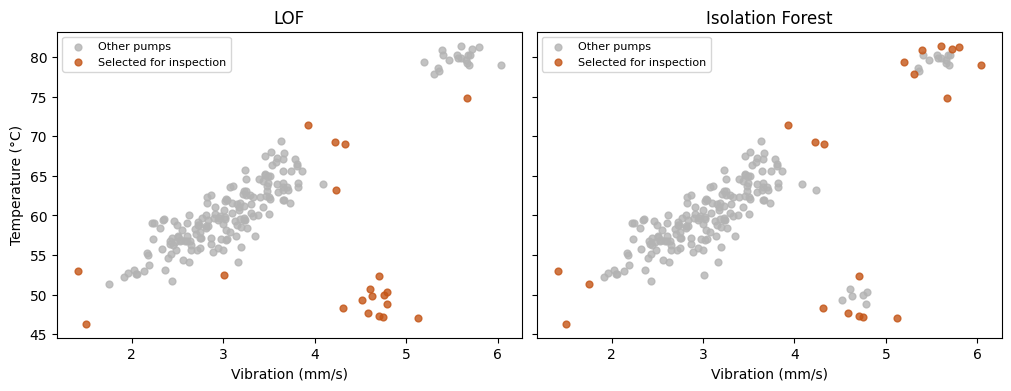

In [2]:
pump_lof = LocalOutlierFactor(n_neighbors=15).fit(pump_X)
pump_forest = IsolationForest(n_estimators=300, max_samples=200, random_state=7130).fit(pump_X)
pump_scores = pd.DataFrame({
    "LOF": -pump_lof.negative_outlier_factor_,
    "Isolation Forest": -pump_forest.score_samples(pump_X),
}, index=pumps.index)

inspection_selected = pd.DataFrame(False, index=pumps.index, columns=pump_scores.columns)
for method in pump_scores:
    inspection_selected.loc[pump_scores[method].nlargest(20).index, method] = True
display(inspection_selected.sum().rename("Pumps selected").to_frame())
print("Pumps selected by both methods:", int(inspection_selected.all(axis=1).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True, layout="constrained")
for method, ax in zip(pump_scores.columns, axes):
    chosen = inspection_selected[method]
    for mask, color, label in [(~chosen, "0.7", "Other pumps"),
                               (chosen, "#c45517", "Selected for inspection")]:
        rows = pumps.loc[mask]
        ax.scatter(rows["vibration_mm_s"], rows["temperature_c"],
                   color=color, label=label, s=24, alpha=0.8)
    ax.set(title=method, xlabel="Vibration (mm/s)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Temperature (°C)")
plt.show()

In [ ]:
# Compare fault-detection performance of the two inspection policies

results = []

for method in inspection_selected.columns:
    selected = inspection_selected[method]

    faults_found = pumps.loc[selected, "confirmed_fault"].sum()
    fault_rate = pumps.loc[selected, "confirmed_fault"].mean()

    results.append({
        "Method": method,
        "Faults Found": int(faults_found),
        "Precision": fault_rate
    })

performance = pd.DataFrame(results).set_index("Method")
display(performance)

### Your Work

,Faults Found,Precision
Method,,
LOF,12,0.6
Isolation Forest,6,0.3


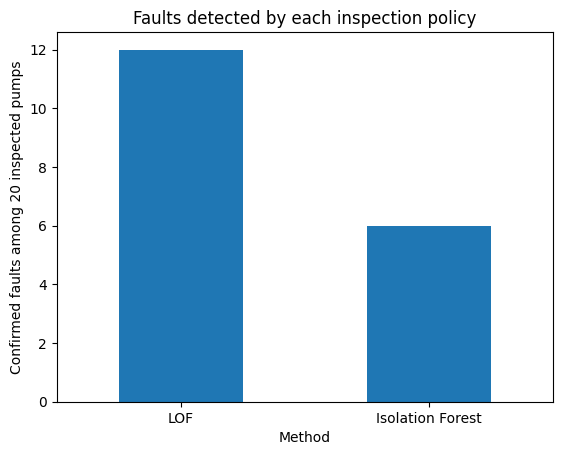

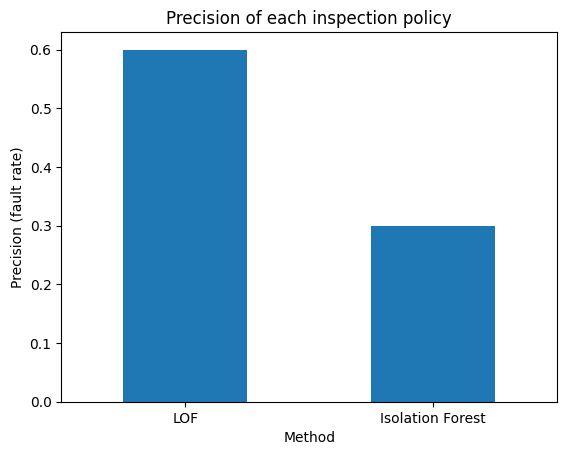

In [4]:
# Compare fault-detection performance of the two inspection policies

results = []

for method in inspection_selected.columns:
    selected = inspection_selected[method]

    faults_found = pumps.loc[selected, "confirmed_fault"].sum()
    fault_rate = pumps.loc[selected, "confirmed_fault"].mean()

    results.append({
        "Method": method,
        "Faults Found": int(faults_found),
        "Precision": fault_rate
    })

performance = pd.DataFrame(results).set_index("Method")
display(performance)

performance["Faults Found"].plot(
    kind="bar",
    ylabel="Confirmed faults among 20 inspected pumps",
    title="Faults detected by each inspection policy",
    rot=0
)
plt.show()

performance["Precision"].plot(
    kind="bar",
    ylabel="Precision (fault rate)",
    title="Precision of each inspection policy",
    rot=0
)
plt.show()

> # Interpretation and Specific Claim
> Both LOF and Isolation Forest select 20 pumps for inspection, and the methods agree on 12 pumps. The scatterplots show that both methods prioritize pumps with unusual vibration and temperature measurements. My initial claim is that LOF appears more effective for prioritizing inspections because it identifies unusual pumps that are more likely to contain confirmed faults.
> # Additional Analysis
> To evaluate the inspection policies, I compared the number of confirmed faults found among the 20 pumps selected by each method and calculated precision (confirmed faults divided by pumps inspected).
> | Method |	Faults Found |	Precision |
> | :--- | :---: | :---: |
> | LOF |	12 |	0.60 |
> | Isolation Forest |	6 |	0.30 |
> 
> The accompanying bar charts show both the number of detected faults and the precision for each method.
> 
> ![LOF vs Isolation Forest](faults_detected.png)
> ![LOF vs Isolation Forest](precision.png)
> # Interpretation of Added Evidence and Recommendation
> The results support my claim that LOF is the better inspection-prioritization method. LOF identified 12 confirmed faults among the 20 inspected pumps, while Isolation Forest identified only 6. This corresponds to precision values of 60% and 30%, respectively. Since Harbor Supply can inspect only 20 pumps per batch, maximizing confirmed faults within those inspections is the most important objective. 
> Because LOF detected twice as many faults as Isolation Forest using the same inspection budget, I recommend that Harbor Supply use Local Outlier Factor (LOF) to prioritize future inspections. These results suggest that LOF provides a more effective use of limited maintenance resources.

## Problem 3 — Time Series: Choosing a Planning Forecast

### The Problem

Harbor Supply uses monthly demand forecasts to plan its warehouse's outbound workload. It is considering a time-only linear regression and a component procedure that combines an extrapolated trend-cycle with repeated monthly seasonal effects.

**Research question:** Which forecasting procedure, if either, should Harbor Supply use as the basis for monthly throughput planning?

An analyst has compared the two procedures using a historical forecast made at the end of December 2024. Both were fitted using January 2017–December 2024 and predicted the same twelve months of 2025. The observed 2025 demand is now available to evaluate their performance and inform the choice for future planning.

The records are synthetic and contain 108 consecutive monthly observations.

| Column | Meaning |
| --- | --- |
| `month` | Calendar month, labeled by its first day |
| `demand_pallets` | Total requested outbound volume that month, in standardized pallet equivalents, rounded to whole pallets |

A month's total becomes known after that month ends.

### Supplied Analysis

Run the following cells. The setup prepares the monthly date index and chronological split. Both procedures use only the training observations to estimate their fitted quantities. The comparison uses the same twelve evaluation dates and reports errors in pallets.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.seasonal import seasonal_decompose

data_url = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/main/"
    "tests/test2/data/monthly-distributor-demand.csv"
)
paths = [Path("data/monthly-distributor-demand.csv"),
         Path("content/tests/test2/data/monthly-distributor-demand.csv")]
data_source = next((path for path in paths if path.is_file()), data_url)
records = pd.read_csv(data_source, parse_dates=["month"], index_col="month")
demand = records["demand_pallets"].astype(float)
assert demand.index.equals(pd.date_range("2017-01-01", "2025-12-01", freq="MS"))
assert demand.notna().all()
training = demand.loc[:"2024-12-01"]
test = demand.loc["2025-01-01":]
print(f"Training: {training.index[0]:%Y-%m}–{training.index[-1]:%Y-%m} ({len(training)} months)")
print(f"Evaluation: {test.index[0]:%Y-%m}–{test.index[-1]:%Y-%m} ({len(test)} months)")

Training: 2017-01–2024-12 (96 months)
Evaluation: 2025-01–2025-12 (12 months)


In [6]:
# Time-only regression on observed training demand.
elapsed = pd.DataFrame({"month_number": np.arange(len(demand))}, index=demand.index)
X_train = elapsed.loc[training.index]
X_test = elapsed.loc[test.index]
baseline_model = LinearRegression().fit(X_train, training)
baseline_forecast = pd.Series(baseline_model.predict(X_test), index=test.index)

# Classical additive decomposition of training demand, with a linear trend-cycle forecast.
parts = seasonal_decompose(training, model="additive", period=12)
trend_data = pd.DataFrame({
    "month_number": X_train["month_number"], "trend_cycle": parts.trend,
}).dropna()
trend_model = LinearRegression().fit(trend_data[["month_number"]], trend_data["trend_cycle"])
trend_forecast = pd.Series(trend_model.predict(X_test), index=test.index)
monthly_effects = parts.seasonal.groupby(parts.seasonal.index.month).mean()
seasonal_forecast = pd.Series(monthly_effects.loc[test.index.month].to_numpy(), index=test.index)
component_forecast = trend_forecast + seasonal_forecast

predictions = pd.DataFrame({"Time only": baseline_forecast, "Component": component_forecast})

,MAE (pallets),RMSE (pallets)
Time only,57.67,73.11
Component,50.70,55.78


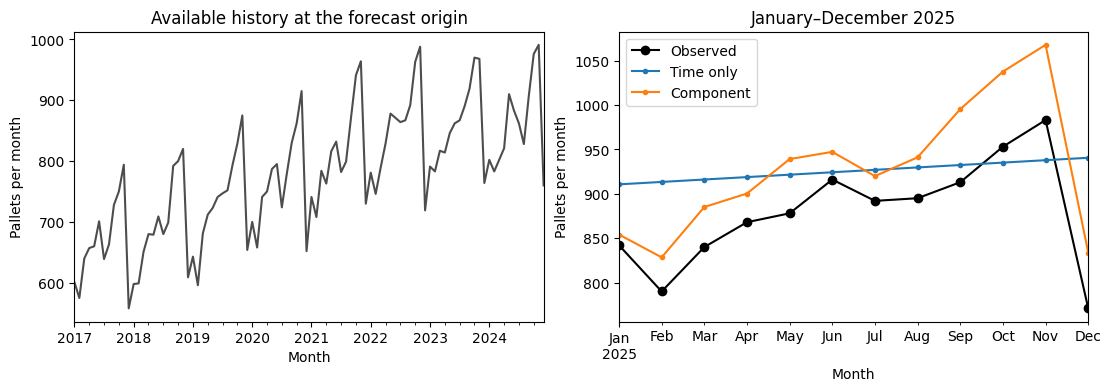

In [7]:
assert predictions.index.equals(test.index)
assert np.isfinite(predictions.to_numpy()).all()
forecast_errors = predictions.rsub(test, axis="index")
forecast_scores = pd.DataFrame({
    "MAE (pallets)": forecast_errors.abs().mean(),
    "RMSE (pallets)": np.sqrt(forecast_errors.pow(2).mean()),
})
display(forecast_scores.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
training.plot(ax=axes[0], color="0.3")
axes[0].set(title="Available history at the forecast origin", xlabel="Month", ylabel="Pallets per month")
test.plot(ax=axes[1], color="black", marker="o", label="Observed")
predictions.plot(ax=axes[1], marker=".")
axes[1].set(title="January–December 2025", xlabel="Month", ylabel="Pallets per month")
axes[1].legend()
plt.show()

### Your Work

,Time only,Component
month,,
2025-01-01,68.6,12.1
2025-02-01,123.3,38.4
2025-03-01,76.0,45.1
2025-04-01,50.8,32.3
2025-05-01,43.5,61.1
2025-06-01,8.2,31.2
2025-07-01,34.9,27.9
2025-08-01,34.6,46.0
2025-09-01,19.4,82.3


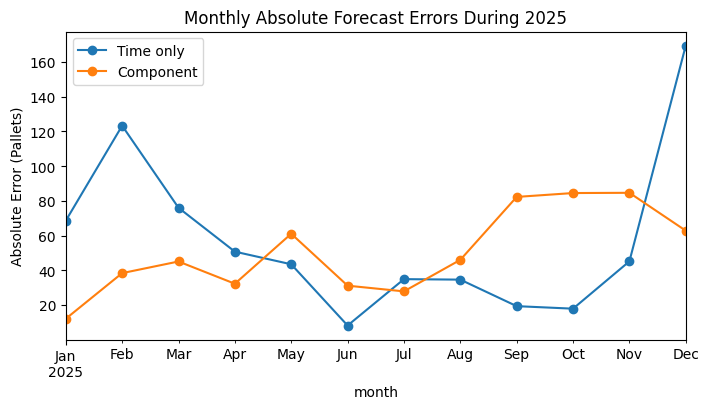

In [8]:
# Compare absolute forecast errors by month

abs_errors = forecast_errors.abs()

display(abs_errors.round(1))

abs_errors.plot(
    marker="o",
    figsize=(8,4),
    ylabel="Absolute Error (Pallets)",
    title="Monthly Absolute Forecast Errors During 2025"
)
plt.show()

> # Interpretation and Specific Claim
> The supplied results indicate that the Component forecasting procedure is more accurate overall than the Time-only regression. The Component model has a lower MAE (50.70 pallets versus 57.67 pallets) and a lower RMSE (55.78 pallets versus 73.11 pallets). My initial claim is that Harbor Supply should use the Component forecasting procedure for monthly throughput planning because it better captures the seasonal patterns visible in the historical demand data.
> # Additional Analysis
> To investigate why the Component model achieved better overall accuracy, I compared the absolute forecast error for each month of 2025. The table and chart show that neither model is best in every month. The Component model has substantially smaller errors during January through April and again in December, while the Time-only model performs better during several months in the second half of the year, particularly September through November.
> 
> | Month | Time only |	Component |
> | :--- | :---: | :---: |
> | Jan. |	68.6 |	12.1 |
> | Feb. |	123.3 |	38.4 |
> | Mar. |	76.0 |	45.1 |
> | Apr. |	50.8 |	32.3 |
> | May. |	43.5 |	61.1 |
> | Jun. |	8.2 |	31.2 |
> | Jul. |	34.9 |	27.9 |
> | Aug. |	34.6 |	46.0 |
> | Sep. |	19.4 |	82.3 |
> | Oct. |	17.9 |	84.5 |
> | Nov. |	45.2 |	84.7 |
> | Dec. |	169.5 |	62.8 |
> 
> ![Monthly Absolute Forecast Errors](forecast_error.png)
> 
> # Interpretation of Added Evidence and Recommendation
> The monthly error analysis qualifies my original claim. Although the Component model does not outperform the Time-only model every month, its improvements during several months are large enough to produce lower overall MAE and RMSE values. This suggests that modeling seasonality provides important forecasting benefits, especially during months when demand deviates substantially from a simple linear trend.
> 
> The Time-only regression generates a relatively smooth forecast and sometimes performs better when actual demand remains close to the long-term trend. However, Harbor Supply must plan warehouse capacity throughout the entire year, including months with strong seasonal effects. The Component model is better suited to this objective because it explicitly incorporates repeating monthly seasonal patterns and delivers superior overall forecast accuracy.
> 
> Therefore, I recommend that Harbor Supply use the Component forecasting procedure as the basis for monthly throughput planning. While it is not the most accurate model in every month, its lower MAE and RMSE demonstrate that it provides the most reliable forecasts overall and is better able to account for seasonal demand fluctuations.
> 
> One additional consideration is that the relative costs of underforecasting and overforecasting were not provided. If Harbor Supply determines that underforecasting demand is substantially more costly than overforecasting, management may wish to examine forecast bias in addition to MAE and RMSE. However, based solely on the evidence provided, the Component model remains the preferred choice because it achieves lower overall forecast errors.

## Assistance Disclosure

Identify material assistance and how you checked it, or write `None`.

> I used Microsoft Copilot for writing and interpretation assistance. All conclusions were verified against the notebook outputs and generated analyses.